# Assignment 2 – Detection of Metal Ring

**Goal:** Detect whether a plastic product contains a metal ring insert.  
Each object is labeled **OK** (ring present) or **NOK** (ring missing).

---

## 1. System Design & Calculations

| Parameter | Value |
|---|---|
| Conveyor belt width | 70 mm |
| Object speed | 100 mm/s |
| Working distance (WD) | 190 mm |
| Max allowed blur | ≤ 1 pixel |

### Selected Equipment

| Component | Selection | Reason |
|---|---|---|
| Camera | Basler acA1920-40gc (1920 × 1200 px) | Available in lab |
| Pixel size | 5.86 µm | Sensor spec |
| Lens | C-mount **12 mm** | Appropriate FOV at 190 mm WD |
| Lighting | Front **ring light** (white LED) | Uniform illumination, enhances color contrast of metal ring |
| Aperture | f/4 | Good depth of field at short exposure |

### Lens & FOV Calculations

$$m = \\frac{f}{WD - f} = \\frac{12}{190 - 12} \\approx 0.067$$

$$FOV_w = \\frac{N_x \\cdot p_{sensor}}{m} = \\frac{1920 \\times 0.00586\\,\\text{mm}}{0.067} \\approx 168\\,\\text{mm}$$

### Scene Pixel Size

$$\\delta = \\frac{p_{sensor}}{m} = \\frac{0.00586\\,\\text{mm}}{0.067} \\approx 0.087\\,\\text{mm/px}$$

### Maximum Exposure Time

$$\\boxed{t_{exp,max} = \\frac{\\delta}{v} = \\frac{0.087\\,\\text{mm}}{100\\,\\text{mm/s}} = 870\\,\\mu s}$$

---

## 2. Detection Approach — Ring Zone Color Analysis

Several approaches were tested:

| Approach | Problem |
|---|---|
| Full-object color detection | Background leaks into bounding box → false positives |
| Hough circle completeness | Plastic cap geometry also forms circles → misclassification |
| Contour hierarchy (RETR_TREE) | Plastic cap already has nested contours without a ring |
| **Ring zone color analysis** | **Works reliably — huge gap between OK and NOK ratios** |

The key insight: analyze only the **annular zone** at 18–50% of the object radius from its center — where a ring physically sits. The metal ring produces a strong gold/brass color response there, while bare plastic does not.

Measured gold pixel ratios in the ring zone from real images:
- **OK cap (ring present):** ~40–55% gold pixels
- **NOK cap (no ring):** ~5–7% gold pixels
- **Threshold used:** 15% — gives a large safety margin


## 2. Import Libraries


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

print('OpenCV:', cv2.__version__)
print('NumPy :', np.__version__)

OpenCV: 4.13.0
NumPy : 2.4.2


## 3. Settings

Place input images (JPG / PNG / BMP) inside `images/input/`. Results go to `images/output/`.

**When to adjust:**
- Objects not detected → try lowering values in `DARK_THRESHOLDS`
- OK caps wrongly NOK → lower `GOLD_RATIO_THRESH` (e.g. 0.10)
- NOK caps wrongly OK → raise `GOLD_RATIO_THRESH` (e.g. 0.20)
- Ring not in center → adjust `RING_INNER_FRAC` / `RING_OUTER_FRAC`


In [2]:
INPUT_FOLDER  = 'images/input'
OUTPUT_FOLDER = 'images/output'

# Object segmentation - tries multiple thresholds automatically
DARK_THRESHOLDS   = [75, 95, 115]  # grayscale levels tried for object detection
MIN_OBJECT_AREA   = None           # None = auto (10% of shorter image dim, squared)
MIN_CIRCULARITY   = 0.45           # caps are roughly circular
MAX_ASPECT_RATIO  = 1.6            # max width/height ratio

# Ring zone: annular region around object center where ring physically sits
RING_INNER_FRAC   = 0.18   # inner boundary (18% of object radius)
RING_OUTER_FRAC   = 0.50   # outer boundary (50% of object radius)

# Gold/brass color range in HSV (OpenCV H: 0-180 scale)
# For silver rings: change HUE to 90-130, lower SAT_MIN
GOLD_HUE_MIN  = 20
GOLD_HUE_MAX  = 70
GOLD_SAT_MIN  = 35
GOLD_VAL_MIN  = 50

# Classification threshold
# OK caps: ~0.40-0.55  |  NOK caps: ~0.05-0.07  |  Threshold: 0.15 (large margin)
GOLD_RATIO_THRESH = 0.15

os.makedirs(OUTPUT_FOLDER, exist_ok=True)
print(f'Input  : {INPUT_FOLDER}')
print(f'Output : {OUTPUT_FOLDER}')

Input  : images/input
Output : images/output


## 4. Core Functions


In [3]:
def find_objects(gray_img, params):
    """Robustly segment objects using multiple thresholds + IoU deduplication."""
    h, w = gray_img.shape
    min_area = params['MIN_OBJECT_AREA'] or (min(h, w) * 0.10) ** 2
    max_area = (min(h, w) * 0.55) ** 2
    blur = cv2.GaussianBlur(gray_img, (15, 15), 0)
    all_cnts = []
    for thr in params['DARK_THRESHOLDS']:
        _, mask = cv2.threshold(blur, thr, 255, cv2.THRESH_BINARY_INV)
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (20, 20))
        proc = cv2.morphologyEx(cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k), cv2.MORPH_OPEN, k)
        cnts, _ = cv2.findContours(proc, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        all_cnts.extend(cnts)
    all_cnts = sorted(all_cnts, key=cv2.contourArea, reverse=True)
    valid, boxes, margin = [], [], 20
    for cnt in all_cnts:
        area = cv2.contourArea(cnt)
        if not (min_area <= area <= max_area):
            continue
        x, y, bw, bh = cv2.boundingRect(cnt)
        if max(bw, bh) / max(min(bw, bh), 1) > params['MAX_ASPECT_RATIO']:
            continue
        perim = cv2.arcLength(cnt, True)
        circ = (4 * np.pi * area / perim**2) if perim > 0 else 0
        if circ < params['MIN_CIRCULARITY']:
            continue
        if (x < margin and bw < w * 0.25) or (y < margin and bh < h * 0.25):
            continue
        box = (x, y, x+bw, y+bh)
        dup = False
        for bx in boxes:
            ix1=max(box[0],bx[0]); iy1=max(box[1],bx[1])
            ix2=min(box[2],bx[2]); iy2=min(box[3],bx[3])
            if ix2>ix1 and iy2>iy1:
                inter=(ix2-ix1)*(iy2-iy1)
                a1=(box[2]-box[0])*(box[3]-box[1]); a2=(bx[2]-bx[0])*(bx[3]-bx[1])
                if inter/(a1+a2-inter) > 0.35:
                    dup=True; break
        if not dup:
            valid.append(cnt); boxes.append(box)
    return valid


def classify_object(roi_bgr, roi_gray, params):
    """
    Classify one object: OK (ring present) or NOK (ring absent).
    Uses gold color ratio in the ring zone (annular region around center).
    Returns: label, gold_ratio, cx, cy, obj_r
    """
    h, w = roi_gray.shape
    hsv_roi = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2HSV)
    # Centroid of dark object body
    blur = cv2.GaussianBlur(roi_gray, (9, 9), 0)
    _, dark = cv2.threshold(blur, 110, 255, cv2.THRESH_BINARY_INV)
    M = cv2.moments(dark)
    cx = int(M['m10']/M['m00']) if M['m00']>0 else w//2
    cy = int(M['m01']/M['m00']) if M['m00']>0 else h//2
    # Object radius
    Y, X = np.ogrid[:h, :w]
    dist = np.sqrt((X-cx)**2 + (Y-cy)**2)
    dark_d = dist[dark>0]
    obj_r = float(np.percentile(dark_d, 85)) if len(dark_d)>0 else float(min(cx,cy)*0.85)
    # Ring zone mask
    ring_zone = (dist >= obj_r*params['RING_INNER_FRAC']) & (dist <= obj_r*params['RING_OUTER_FRAC'])
    # Gold color mask
    gold_lo = np.array([params['GOLD_HUE_MIN'], params['GOLD_SAT_MIN'], params['GOLD_VAL_MIN']])
    gold_hi = np.array([params['GOLD_HUE_MAX'], 255, 255])
    gold_mask = cv2.inRange(hsv_roi, gold_lo, gold_hi)
    # Ratio
    gold_ratio = (int(gold_mask[ring_zone].sum())//255) / max(int(ring_zone.sum()), 1)
    label = 'OK' if gold_ratio >= params['GOLD_RATIO_THRESH'] else 'NOK'
    return label, round(gold_ratio, 4), cx, cy, int(obj_r)


def process_image(image_bgr, params):
    """Full pipeline: detect objects, classify, annotate. Returns (annotated, results)."""
    annotated = image_bgr.copy()
    img_h, img_w = image_bgr.shape[:2]
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    objects = find_objects(gray, params)
    results = []
    for cnt in objects:
        x, y, bw, bh = cv2.boundingRect(cnt)
        label, gold_ratio, rcx, rcy, obj_r = classify_object(
            image_bgr[y:y+bh, x:x+bw], gray[y:y+bh, x:x+bw], params)
        color = (0,200,0) if label=='OK' else (0,0,220)
        pad=8
        x1=max(0,x-pad); y1=max(0,y-pad)
        x2=min(img_w,x+bw+pad); y2=min(img_h,y+bh+pad)
        cv2.rectangle(annotated,(x1,y1),(x2,y2),color,3)
        if label=='OK':
            cv2.circle(annotated,(x+rcx,y+rcy),int(obj_r*params['RING_INNER_FRAC']),(0,220,220),1)
            cv2.circle(annotated,(x+rcx,y+rcy),int(obj_r*params['RING_OUTER_FRAC']),(0,220,220),2)
        font=cv2.FONT_HERSHEY_SIMPLEX
        (tw,th),base=cv2.getTextSize(label,font,1.0,2)
        cv2.rectangle(annotated,(x1,y1-th-base-6),(x1+tw+6,y1),color,cv2.FILLED)
        cv2.putText(annotated,label,(x1+3,y1-base-3),font,1.0,(255,255,255),2,cv2.LINE_AA)
        if label=='NOK':
            cx_abs=(x1+x2)//2; cy_abs=(y1+y2)//2
            loc_txt=f'Ring missing @ ({cx_abs},{cy_abs})'
            cv2.putText(annotated,loc_txt,(x1+4,y2-8),cv2.FONT_HERSHEY_SIMPLEX,0.50,(0,0,220),1,cv2.LINE_AA)
        # Show defect location on NOK objects
        if label == 'NOK':
            cx_abs = (x1 + x2) // 2
            cy_abs = (y1 + y2) // 2
            loc_text = f'Ring missing at ({cx_abs},{cy_abs})'
            cv2.putText(annotated, loc_text, (x1+3, y2-8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,0,220), 1, cv2.LINE_AA)
        results.append({'bbox':(x1,y1,x2,y2),'label':label,'gold_ratio':gold_ratio,
                        'defect_location': ((x1+x2)//2,(y1+y2)//2) if label=='NOK' else None})
    n_ok=sum(1 for r in results if r['label']=='OK')
    n_nok=len(results)-n_ok
    verdict='PASS' if n_nok==0 and len(results)>0 else 'FAIL'
    v_col=(0,200,0) if verdict=='PASS' else (0,0,220)
    lines=[(f'Objects : {len(results)}',(255,255,255)),(f'OK      : {n_ok}',(80,220,80)),
           (f'NOK     : {n_nok}',(80,80,255)),(verdict,v_col)]
    cv2.rectangle(annotated,(5,5),(230,len(lines)*36+10),(20,20,20),cv2.FILLED)
    cv2.rectangle(annotated,(5,5),(230,len(lines)*36+10),(160,160,160),1)
    for i,(txt,col) in enumerate(lines):
        cv2.putText(annotated,txt,(12,35+i*36),cv2.FONT_HERSHEY_SIMPLEX,0.85,col,2,cv2.LINE_AA)
    return annotated, results


print('Functions defined successfully.')

Functions defined successfully.


## 5. Run on All Images


In [4]:
PARAMS = {
    'DARK_THRESHOLDS'  : DARK_THRESHOLDS,
    'MIN_OBJECT_AREA'  : MIN_OBJECT_AREA,
    'MIN_CIRCULARITY'  : MIN_CIRCULARITY,
    'MAX_ASPECT_RATIO' : MAX_ASPECT_RATIO,
    'RING_INNER_FRAC'  : RING_INNER_FRAC,
    'RING_OUTER_FRAC'  : RING_OUTER_FRAC,
    'GOLD_HUE_MIN'     : GOLD_HUE_MIN,
    'GOLD_HUE_MAX'     : GOLD_HUE_MAX,
    'GOLD_SAT_MIN'     : GOLD_SAT_MIN,
    'GOLD_VAL_MIN'     : GOLD_VAL_MIN,
    'GOLD_RATIO_THRESH': GOLD_RATIO_THRESH,
}

EXTENSIONS  = {'.jpg','.jpeg','.png','.bmp','.tif','.tiff'}
image_paths = sorted([p for p in Path(INPUT_FOLDER).iterdir() if p.suffix.lower() in EXTENSIONS])

if not image_paths:
    print(f"No images found in '{INPUT_FOLDER}'. Add your images and re-run.")
else:
    print(f'Found {len(image_paths)} image(s)\n')
    print(f"{'Image':<35} {'Objects':>7} {'OK':>5} {'NOK':>5} {'Result':>7}")
    print('-'*62)

all_results = []

for img_path in image_paths:
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print(f'  [WARN] Cannot read {img_path.name}')
        continue
    annotated, results = process_image(img_bgr, PARAMS)
    cv2.imwrite(str(Path(OUTPUT_FOLDER)/img_path.name), annotated)
    n_ok=sum(1 for r in results if r['label']=='OK')
    n_nok=len(results)-n_ok
    verdict='PASS' if n_nok==0 and len(results)>0 else 'FAIL'
    print(f"{img_path.name:<35} {len(results):>7} {n_ok:>5} {n_nok:>5} {verdict:>7}")
    for r in results:
        print(f"    {r['label']}  gold_ratio={r['gold_ratio']}  bbox={r['bbox']}")
    all_results.append({'file':img_path.name,'detections':results,'verdict':verdict})

print(f"\nDone. Results saved to '{OUTPUT_FOLDER}'")

Found 10 image(s)

Image                               Objects    OK   NOK  Result
--------------------------------------------------------------
1.bmp                                     3     2     1    FAIL
    OK  gold_ratio=0.411  bbox=(1062, 133, 1420, 491)
    NOK  gold_ratio=0.0863  bbox=(983, 647, 1339, 1001)
    OK  gold_ratio=0.4452  bbox=(489, 390, 839, 743)
10.bmp                                    2     1     1    FAIL
    NOK  gold_ratio=0.0646  bbox=(1126, 428, 1484, 785)
    OK  gold_ratio=0.4447  bbox=(576, 251, 928, 605)
2.bmp                                     2     2     0    PASS
    OK  gold_ratio=0.4113  bbox=(1063, 125, 1421, 483)
    OK  gold_ratio=0.4413  bbox=(491, 384, 841, 737)
3.bmp                                     2     0     2    FAIL
    NOK  gold_ratio=0.0734  bbox=(1035, 581, 1391, 935)
    NOK  gold_ratio=0.0511  bbox=(717, 197, 1071, 552)
4.bmp                                     3     2     1    FAIL
    NOK  gold_ratio=0.0656  bbox=(1053, 215

## 6. Visualise Results


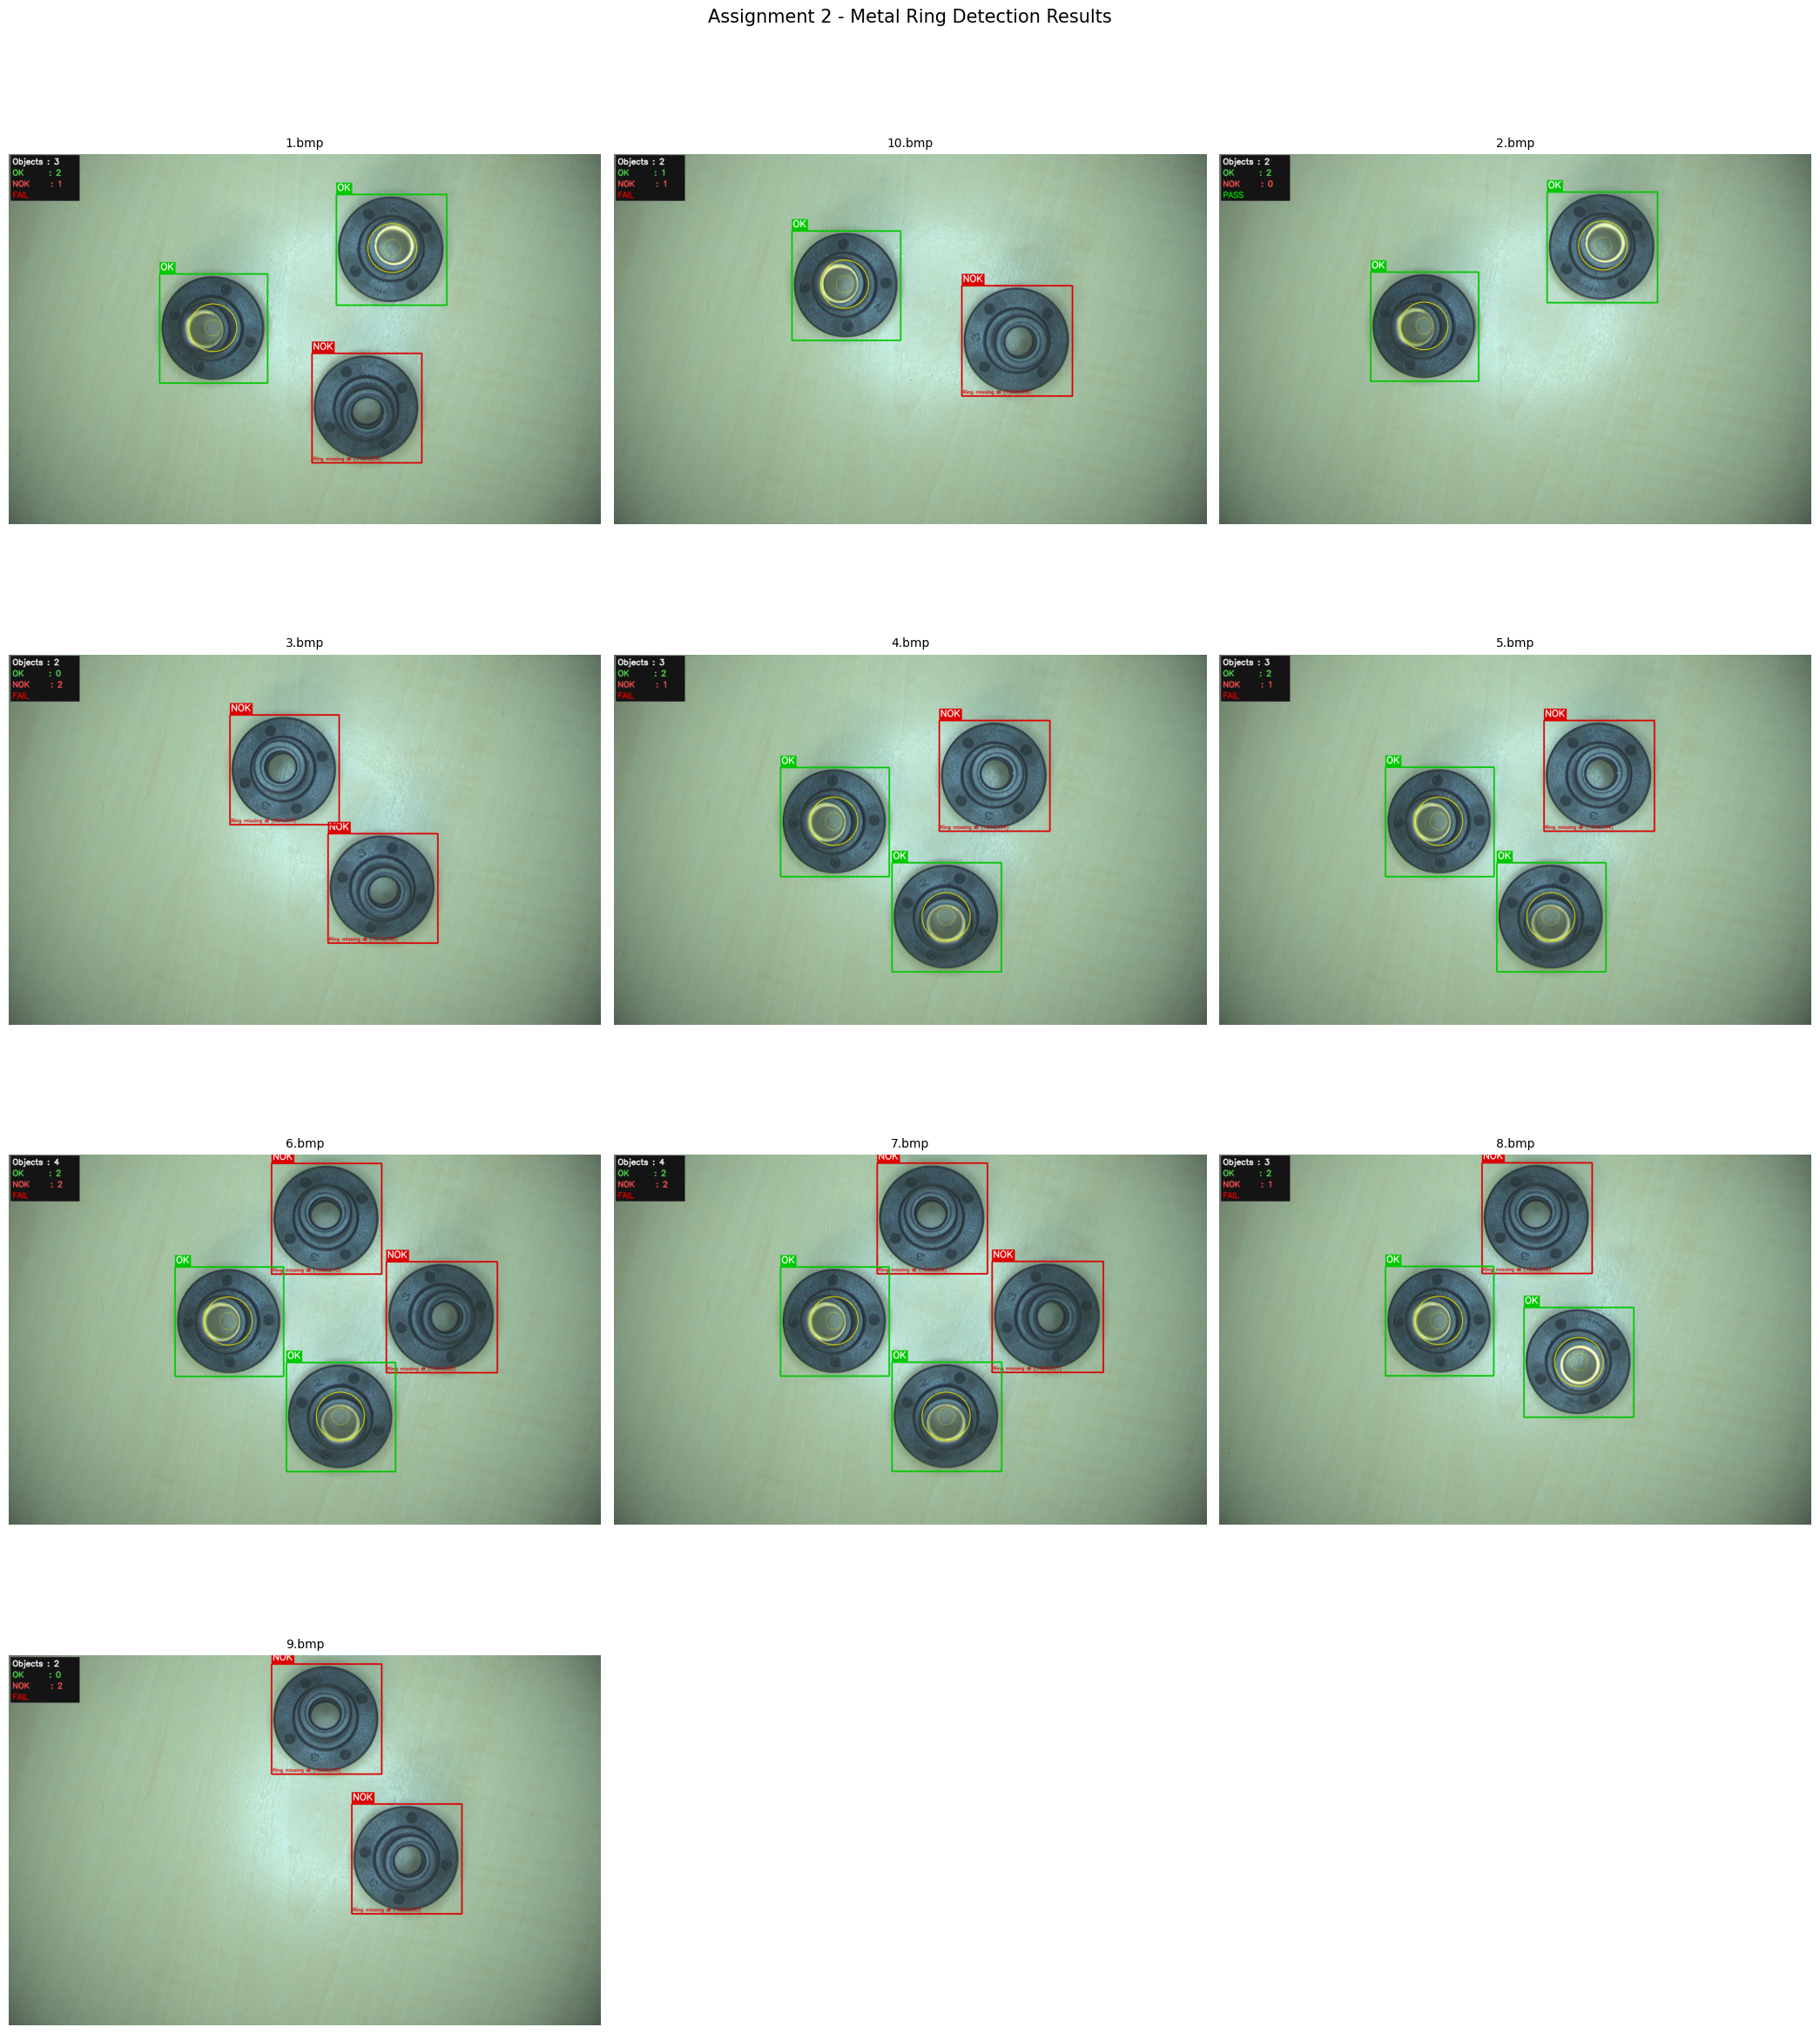

Overview saved as results_overview.png


In [5]:
output_paths = sorted([p for p in Path(OUTPUT_FOLDER).iterdir() if p.suffix.lower() in EXTENSIONS])

if not output_paths:
    print('No output images found. Run Section 5 first.')
else:
    n_cols=3; n_rows=int(np.ceil(len(output_paths)/n_cols))
    fig,axes=plt.subplots(n_rows,n_cols,figsize=(7*n_cols,6*n_rows))
    axes=np.array(axes).flatten()
    for ax,p in zip(axes,output_paths):
        img=cv2.imread(str(p))
        ax.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
        ax.set_title(p.name,fontsize=10); ax.axis('off')
    for ax in axes[len(output_paths):]: ax.set_visible(False)
    plt.suptitle('Assignment 2 - Metal Ring Detection Results',fontsize=15,y=1.01)
    plt.tight_layout()
    plt.savefig('results_overview.png',dpi=120,bbox_inches='tight')
    plt.show()
    print('Overview saved as results_overview.png')

## 7. Debug Helper

Run on any image to see intermediate steps. Change `DEBUG_IMAGE` to the file you want to inspect.


Object (1070,141): OK  gold_ratio=0.4110
Object (991,655): NOK  gold_ratio=0.0863
Object (497,398): OK  gold_ratio=0.4452


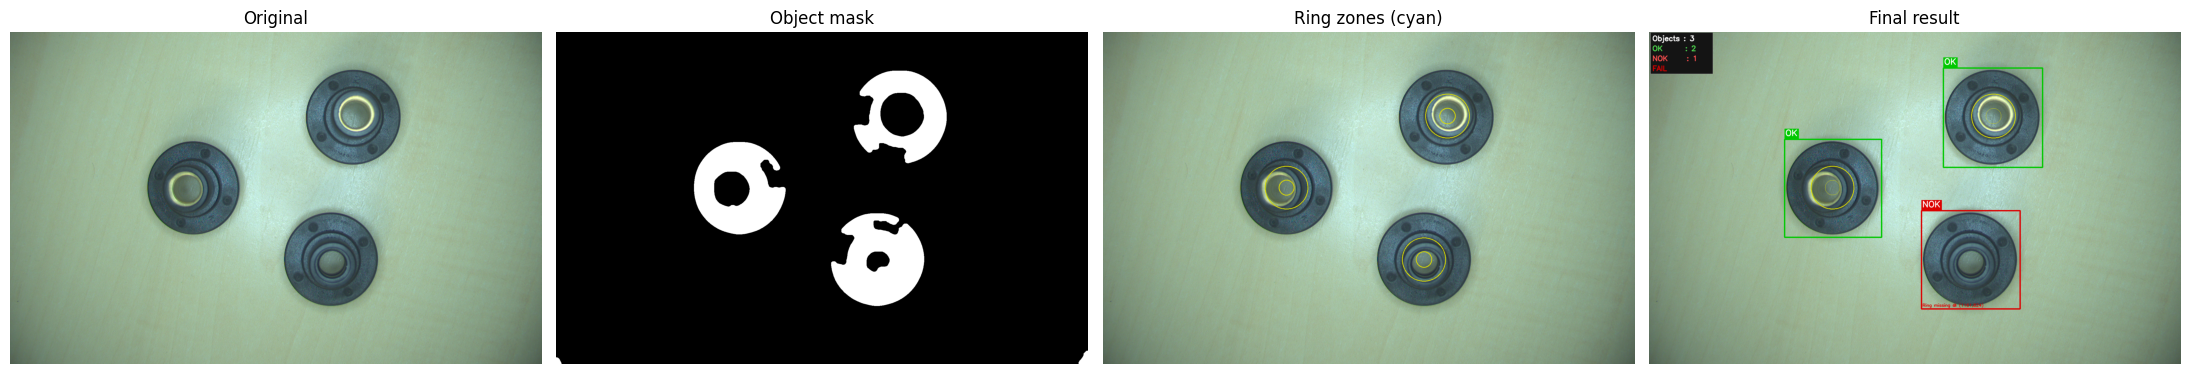

Tuning tips:
  Objects not found?   -> lower DARK_THRESHOLDS (currently [75, 95, 115])
  OK called NOK?       -> lower GOLD_RATIO_THRESH (currently 0.15)
  NOK called OK?       -> raise GOLD_RATIO_THRESH
  Ring zone off?       -> adjust RING_INNER_FRAC/RING_OUTER_FRAC


In [6]:
DEBUG_IMAGE = str(image_paths[0]) if image_paths else ''

if not DEBUG_IMAGE or not Path(DEBUG_IMAGE).exists():
    print('Set DEBUG_IMAGE to a valid path.')
else:
    img_bgr=cv2.imread(DEBUG_IMAGE)
    gray=cv2.cvtColor(img_bgr,cv2.COLOR_BGR2GRAY)
    hsv=cv2.cvtColor(img_bgr,cv2.COLOR_BGR2HSV)
    blur=cv2.GaussianBlur(gray,(15,15),0)
    _,seg=cv2.threshold(blur,DARK_THRESHOLDS[1],255,cv2.THRESH_BINARY_INV)
    k=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(20,20))
    seg=cv2.morphologyEx(cv2.morphologyEx(seg,cv2.MORPH_CLOSE,k),cv2.MORPH_OPEN,k)
    gold_lo=np.array([GOLD_HUE_MIN,GOLD_SAT_MIN,GOLD_VAL_MIN])
    gold_hi=np.array([GOLD_HUE_MAX,255,255])
    gold_vis=cv2.inRange(hsv,gold_lo,gold_hi)
    zone_vis=img_bgr.copy()
    for cnt in find_objects(gray,PARAMS):
        x,y,bw,bh=cv2.boundingRect(cnt)
        label,gr,rcx,rcy,obj_r=classify_object(img_bgr[y:y+bh,x:x+bw],gray[y:y+bh,x:x+bw],PARAMS)
        cv2.circle(zone_vis,(x+rcx,y+rcy),int(obj_r*RING_INNER_FRAC),(0,220,220),2)
        cv2.circle(zone_vis,(x+rcx,y+rcy),int(obj_r*RING_OUTER_FRAC),(0,220,220),2)
        print(f'Object ({x},{y}): {label}  gold_ratio={gr:.4f}')
    result_vis,_=process_image(img_bgr,PARAMS)
    fig,axes=plt.subplots(1,4,figsize=(22,5))
    axes[0].imshow(cv2.cvtColor(img_bgr,cv2.COLOR_BGR2RGB));  axes[0].set_title('Original')
    axes[1].imshow(seg,cmap='gray');                           axes[1].set_title('Object mask')
    axes[2].imshow(cv2.cvtColor(zone_vis,cv2.COLOR_BGR2RGB)); axes[2].set_title('Ring zones (cyan)')
    axes[3].imshow(cv2.cvtColor(result_vis,cv2.COLOR_BGR2RGB));axes[3].set_title('Final result')
    for ax in axes: ax.axis('off')
    plt.tight_layout()
    plt.savefig('debug_output.png',dpi=120,bbox_inches='tight')
    plt.show()
    print('Tuning tips:')
    print(f'  Objects not found?   -> lower DARK_THRESHOLDS (currently {DARK_THRESHOLDS})')
    print(f'  OK called NOK?       -> lower GOLD_RATIO_THRESH (currently {GOLD_RATIO_THRESH})')
    print(f'  NOK called OK?       -> raise GOLD_RATIO_THRESH')
    print(f'  Ring zone off?       -> adjust RING_INNER_FRAC/RING_OUTER_FRAC')

## 8. Summary Table


In [7]:
if not all_results:
    print('Run Section 5 first.')
else:
    tot_obj=tot_ok=tot_nok=0
    print(f"{'Image':<35} {'Objects':>7} {'OK':>5} {'NOK':>5} {'Result':>7}")
    print('='*62)
    for entry in all_results:
        n_obj=len(entry['detections'])
        n_ok=sum(1 for d in entry['detections'] if d['label']=='OK')
        n_nok=n_obj-n_ok
        print(f"{entry['file']:<35} {n_obj:>7} {n_ok:>5} {n_nok:>5} {entry['verdict']:>7}")
        tot_obj+=n_obj; tot_ok+=n_ok; tot_nok+=n_nok
    print('='*62)
    print(f"{'TOTAL':<35} {tot_obj:>7} {tot_ok:>5} {tot_nok:>5}")

Image                               Objects    OK   NOK  Result
1.bmp                                     3     2     1    FAIL
10.bmp                                    2     1     1    FAIL
2.bmp                                     2     2     0    PASS
3.bmp                                     2     0     2    FAIL
4.bmp                                     3     2     1    FAIL
5.bmp                                     3     2     1    FAIL
6.bmp                                     4     2     2    FAIL
7.bmp                                     4     2     2    FAIL
8.bmp                                     3     2     1    FAIL
9.bmp                                     2     0     2    FAIL
TOTAL                                    28    15    13
